## Stage 1: Data Preparation & Exploratory Data Analysis (EDA)


### 1.2. Dataset Structure and Quality Assessment

**Objective:** Examine the structure and quality of the SunoCaps dataset before further analysis.

At this stage, we investigate:
- Dataset dimensions and available features.
- Data types and missing values.
- Duplicate records and potential data quality issues.

This initial inspection helps identify preprocessing requirements and determine which features can support prompt-to-audio validation.


In [76]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/SunoCaps_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (256, 11)


,ytid_V,Comments,Emotion,Extra_emotion,aspect_version,caption_version,shorth_aspect,short_caption,Instrumental,aspect_list,caption
0,-0Gj8-vB1q4_1,Not low quality. No strings,Sad,NaN,True,False,False,True,False,"low quality, sustained strings melody, soft fe...",The low quality recording features a ballad so...
1,-0Gj8-vB1q4_2,Not low quality. No strings,Sad,NaN,True,False,False,True,False,"low quality, sustained strings melody, soft fe...",The low quality recording features a ballad so...
2,-0Gj8-vB1q4_3,No strings,Sad,NaN,False,True,False,True,False,"low quality, sustained strings melody, soft fe...",The low quality recording features a ballad so...
3,-0Gj8-vB1q4_4,No strings. Not clearly a female voice,Sad,NaN,False,True,False,True,False,"low quality, sustained strings melody, soft fe...",The low quality recording features a ballad so...
4,-1UWSisR2zo_1,Not poor audio quality. No ambient noises,Exciting,Energetic,True,False,True,True,False,"live performance, poor audio quality, ambient ...",A male singer sings this groovy melody. The so...


In [77]:

print("COLUMNS AND DATA TYPES:")
print(df.dtypes)

print("\nMISSING VALUES:")
print(df.isna().sum())

print("\nDUPLICATES:")
print(df.duplicated().sum())

print("\nTOTAL ROWS:", len(df))


COLUMNS AND DATA TYPES:
ytid_V             object
Comments           object
Emotion            object
Extra_emotion      object
aspect_version       bool
caption_version      bool
shorth_aspect        bool
short_caption        bool
Instrumental         bool
aspect_list        object
caption            object
dtype: object

MISSING VALUES:
ytid_V              0
Comments           73
Emotion             0
Extra_emotion      60
aspect_version      0
caption_version     0
shorth_aspect       0
short_caption       0
Instrumental        0
aspect_list         0
caption             0
dtype: int64

DUPLICATES:
0

TOTAL ROWS: 256



### 1.3. Feature Exploration

**Objective:** Identify the dataset features relevant to evaluating alignment between AI-generated music and text prompts.

We focus on:
- Text prompts describing the intended music.
- Expert annotations describing generation errors.
- Musical attributes such as emotion and vocals.
- Identifiers linking prompts to generated audio.

These features will form the foundation for prompt parsing, expert annotation processing, and audio-based evaluation.


In [78]:
for col in df.columns:
    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"Data type: {df[col].dtype}")
    print(f"Unique values: {df[col].nunique()}")
    print("Sample values:")
    print(df[col].dropna().head(3).tolist())



Column: ytid_V
Data type: object
Unique values: 256
Sample values:
['-0Gj8-vB1q4_1', '-0Gj8-vB1q4_2', '-0Gj8-vB1q4_3']

Column: Comments
Data type: object
Unique values: 72
Sample values:
['Not low quality. No strings', 'Not low quality. No strings', 'No strings']

Column: Emotion
Data type: object
Unique values: 10
Sample values:
['Sad', 'Sad', 'Sad']

Column: Extra_emotion
Data type: object
Unique values: 44
Sample values:
['Energetic', 'Energetic', 'Energetic']

Column: aspect_version
Data type: bool
Unique values: 2
Sample values:
[True, True, False]

Column: caption_version
Data type: bool
Unique values: 2
Sample values:
[False, False, True]

Column: shorth_aspect
Data type: bool
Unique values: 2
Sample values:
[False, False, False]

Column: short_caption
Data type: bool
Unique values: 2
Sample values:
[True, True, True]

Column: Instrumental
Data type: bool
Unique values: 2
Sample values:
[False, False, False]

Column: aspect_list
Data type: object
Unique values: 64
Sample value


### 1.4. Missing Values Analysis

**Objective:** Analyze the completeness of the SunoCaps dataset and identify potential data quality issues.

Missing values are particularly important in this project because expert annotations, prompt descriptions, and musical attributes are used to evaluate AI-generated music.

We will:
- Calculate the number and percentage of missing values per feature.
- Visualize missing data patterns.
- Identify features that may require special handling during preprocessing.


,Missing Count,Missing (%)
Comments,73,28.52
Extra_emotion,60,23.44
ytid_V,0,0.00
Emotion,0,0.00
aspect_version,0,0.00
caption_version,0,0.00
shorth_aspect,0,0.00
short_caption,0,0.00
Instrumental,0,0.00
aspect_list,0,0.00


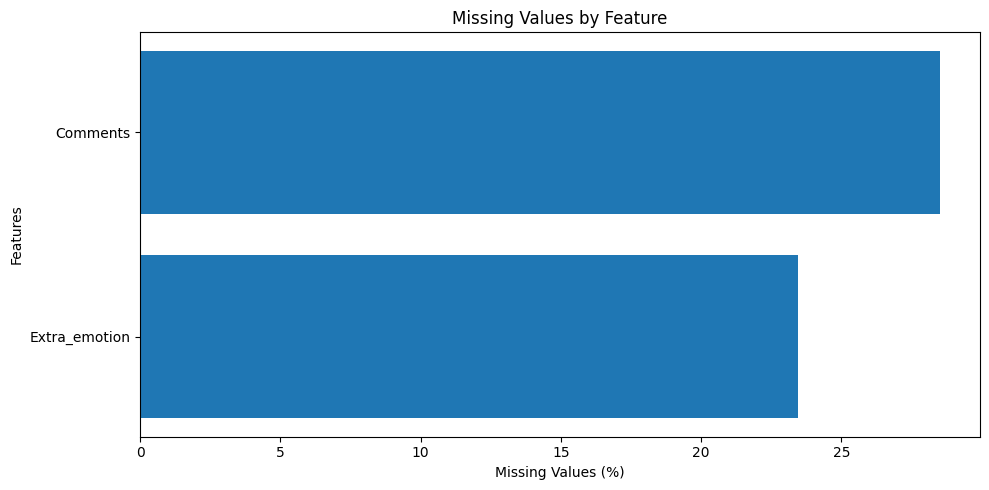

In [79]:

missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing (%)": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_values = missing_values.sort_values(
    by="Missing (%)",
    ascending=False
)

display(missing_values)

missing_plot = missing_values[
    missing_values["Missing Count"] > 0
]

if not missing_plot.empty:
    plt.figure(figsize=(10, 5))
    plt.barh(
        missing_plot.index,
        missing_plot["Missing (%)"]
    )
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Features")
    plt.title("Missing Values by Feature")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected.")



### Findings

The missing values analysis identifies features with incomplete information and highlights potential limitations of the dataset.

In particular, missing expert comments should not automatically be interpreted as evidence that the generated audio fully matches the prompt.

At this stage, missing values are preserved. Decisions about imputation, exclusion, or assigning validation labels will be made after examining the meaning of each feature.


### 1.5. Prompt and Expert Annotation Exploration

**Objective:** Explore textual descriptions and expert annotations to understand how music generation requirements and errors are represented in the dataset.

At this stage, we aim to:
- Identify prompt-related and annotation-related features.
- Examine representative text examples.
- Analyze the length and variability of text descriptions.
- Investigate how expert feedback could be transformed into structured validation labels.

The findings will guide the development of the prompt parsing and expert annotation modules.


In [80]:

text_columns = df.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("Text-based columns:")
for col in text_columns:
    print(f"- {col}")

for col in text_columns:
    print(f"\n{'=' * 60}")
    print(f"COLUMN: {col}")
    display(df[[col]].dropna().head(3))


Text-based columns:
- ytid_V
- Comments
- Emotion
- Extra_emotion
- aspect_list
- caption

COLUMN: ytid_V


,ytid_V
0,-0Gj8-vB1q4_1
1,-0Gj8-vB1q4_2
2,-0Gj8-vB1q4_3



COLUMN: Comments


,Comments
0,Not low quality. No strings
1,Not low quality. No strings
2,No strings



COLUMN: Emotion


...

,Extra_emotion
4,Energetic
5,Energetic
6,Energetic



COLUMN: aspect_list


,aspect_list
0,"low quality, sustained strings melody, soft fe..."
1,"low quality, sustained strings melody, soft fe..."
2,"low quality, sustained strings melody, soft fe..."



COLUMN: caption


,caption
0,The low quality recording features a ballad so...
1,The low quality recording features a ballad so...
2,The low quality recording features a ballad so...


In [81]:

text_stats = []

for col in text_columns:
    values = df[col].dropna().astype(str)

    if values.empty:
        continue

    lengths = values.str.split().str.len()

    text_stats.append({
        "Column": col,
        "Mean Words": round(lengths.mean(), 2),
        "Median Words": round(lengths.median(), 2),
        "Max Words": lengths.max(),
        "Unique Values": values.nunique()
    })

text_stats_df = pd.DataFrame(text_stats)

display(text_stats_df)


,Column,Mean Words,Median Words,Max Words,Unique Values
0,ytid_V,1.00,1.0,1,256
1,Comments,8.39,6.0,33,72
2,Emotion,1.00,1.0,2,10
3,Extra_emotion,1.32,1.0,3,44
4,aspect_list,18.59,18.0,29,64
5,caption,30.86,31.0,38,64


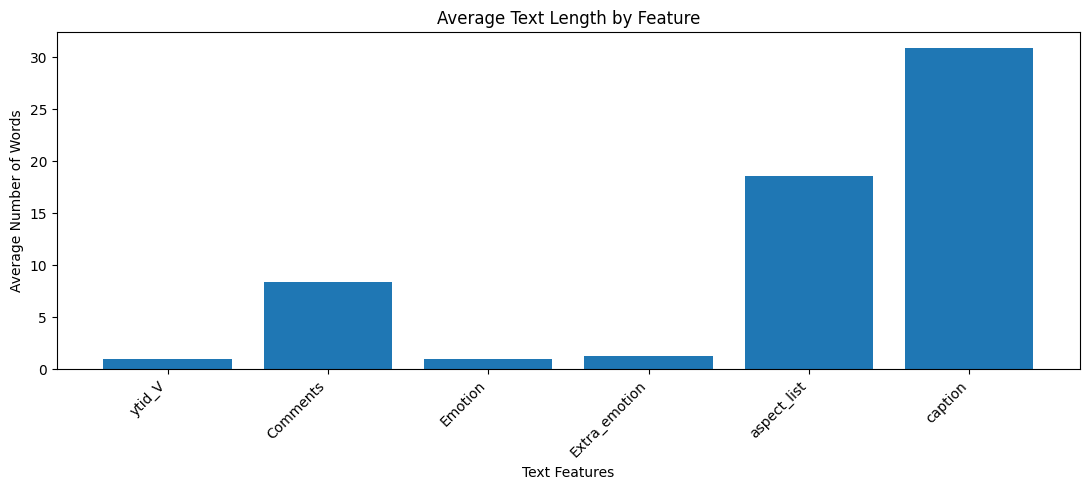

In [82]:

if not text_stats_df.empty:
    plt.figure(figsize=(11, 5))

    plt.bar(
        text_stats_df["Column"],
        text_stats_df["Mean Words"]
    )

    plt.xlabel("Text Features")
    plt.ylabel("Average Number of Words")
    plt.title("Average Text Length by Feature")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()



### Findings

The text exploration provides an initial overview of how prompts and annotations are represented in SunoCaps.

Text length statistics help distinguish short categorical attributes from longer descriptive fields. However, length alone does not establish the semantic purpose of a feature.

The next preprocessing stage will focus on selecting the relevant prompt and expert feedback columns and transforming their contents into structured information suitable for automated evaluation.


### 1.6. Prompt Types and Expert Feedback Analysis

**Objective:** Investigate the relationship between music descriptions and expert feedback.

The SunoCaps dataset includes two prompt representations:
- **Caption:** A natural-language description of the intended music.
- **Aspect list:** A structured list of musical attributes.

Expert comments describe perceived differences between the generated audio and the requested musical characteristics.

In this step, we examine the diversity of expert comments and investigate how feedback varies across generated versions.

This analysis will help us design a structured annotation system for identifying prompt-to-audio mismatches.


,Count
Comments,
[Missing],73
Not low quality,20
"Does not follow ""instrumental"" text command.",8
Not clearly a male voice,6
"Not low quality, no references to it being an in-game audio",4
Added voice,4
Not instrumental,4
Not clearly beatbox,4
No sound of water. No ducks.,4


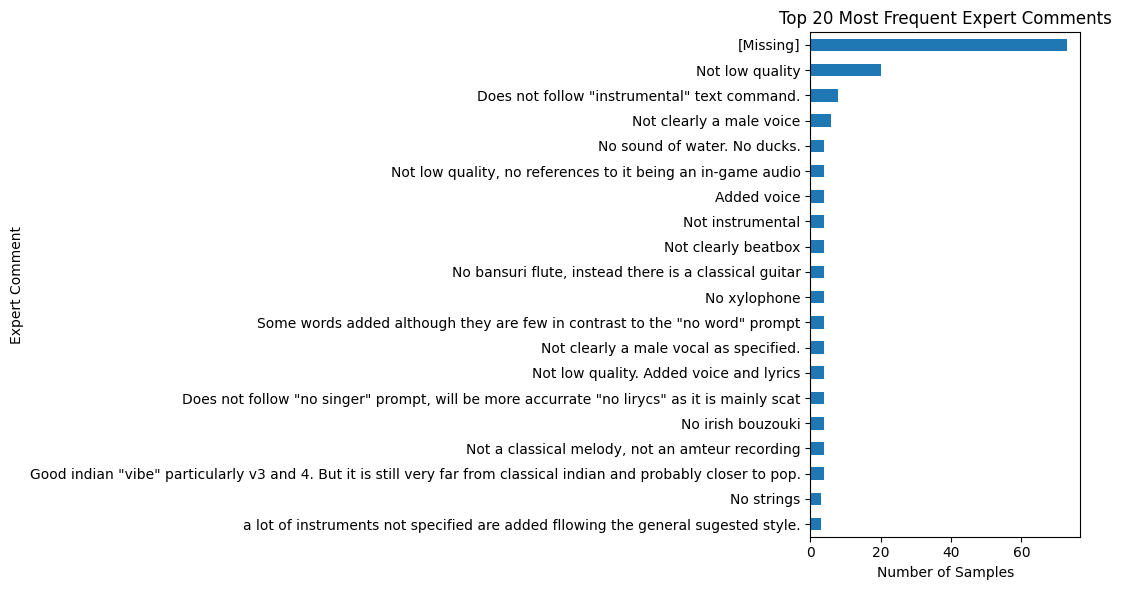

In [83]:

comments_freq = (
    df["Comments"]
    .fillna("[Missing]")
    .value_counts()
    .head(20)
)

display(comments_freq.to_frame("Count"))

plt.figure(figsize=(11, 6))
comments_freq.sort_values().plot(kind="barh")

plt.xlabel("Number of Samples")
plt.ylabel("Expert Comment")
plt.title("Top 20 Most Frequent Expert Comments")
plt.tight_layout()
plt.show()


In [84]:

# Extract original ID and generated version
df["original_id"] = df["ytid_V"].str.rsplit(
    "_", n=1
).str[0]

df["generation_version"] = df["ytid_V"].str.rsplit(
    "_", n=1
).str[-1]

# Check versions per original sample
version_counts = df.groupby(
    "original_id"
)["generation_version"].nunique()

print("Number of original samples:", df["original_id"].nunique())

print("\nGenerated versions per original:")
display(version_counts.value_counts().sort_index())

print("\nSamples by generation version:")
display(df["generation_version"].value_counts().sort_index())


Number of original samples: 64

Generated versions per original:


generation_version
4    64
Name: count, dtype: int64


Samples by generation version:


generation_version
1    64
2    64
3    64
4    64
Name: count, dtype: int64


### Findings

The dataset contains two complementary representations of music descriptions: natural-language captions and aspect lists.

Expert comments provide qualitative feedback about the generated results. Their frequency distribution and differences across generated versions can help identify recurring generation errors.

Grouping tracks by their original MusicCaps identifier enables comparisons between multiple generations of the same musical description.

The next step is to develop a structured taxonomy of mismatches, including genre, instruments, vocals, mood, tempo, and other musical properties.



### 1.7. Emotion Distribution Analysis

**Objective:** Explore the distribution of emotional characteristics in the SunoCaps dataset.

The dataset contains two emotion-related features:
- `Emotion`: Main emotion annotation.
- `Extra_emotion`: Additional emotional descriptors.

We analyze their frequency distributions, missing values, and relationships to identify potential class imbalance and assess their suitability for evaluating emotion classification models.

Since multiple generated tracks originate from the same source prompt, distributions are initially examined at the track level.


In [85]:

# Main emotion distribution
emotion_counts = (
    df["Emotion"]
    .fillna("Missing")
    .value_counts()
)

# Additional emotion distribution
extra_emotion_counts = (
    df["Extra_emotion"]
    .fillna("Missing")
    .value_counts()
)

print("MAIN EMOTION DISTRIBUTION:")
display(emotion_counts.to_frame("Count"))

print("\nADDITIONAL EMOTION DISTRIBUTION:")
display(extra_emotion_counts.to_frame("Count"))

print("\nUNIQUE EMOTIONS:")
print(df["Emotion"].dropna().unique())

print("\nUNIQUE ADDITIONAL EMOTIONS:")
print(df["Extra_emotion"].dropna().unique())


MAIN EMOTION DISTRIBUTION:


,Count
Emotion,
Happy,90
Exciting,54
Sad,40
Calm,26
Content,21
Angry,11
Disgust,7
Surprise,5
"Happy, simple",1



ADDITIONAL EMOTION DISTRIBUTION:


,Count
Extra_emotion,
Missing,60
Energetic,45
Chill,19
Slightly melancholic,13
Exciting,13
Melancholic,11
Relaxing,8
"Relaxing, chill",7
Epic,6



UNIQUE EMOTIONS:
['Sad' 'Exciting' 'Content' 'Happy' 'Surprise' 'Calm' 'Disgust' 'Angry'
 'Happy, simple' 'Happy ']

UNIQUE ADDITIONAL EMOTIONS:
['Energetic' 'Calm' 'Epic' 'Energetic, epic' 'Agressive, epic' 'Exciting'
 'Disgust' 'Chill' 'Relaxing' 'Melancholic, energetic' 'Melancholic'
 'Slightly sad' 'Exciting, energetic' 'Cheerful' 'Slightly melancholic'
 'Relaxing, chill' 'Dreamy' 'Groovy' 'Agressive' 'Aggressive, disgust'
 'Cheerful, slightly melancholic' 'Aggressive' 'Epic, slightly sad'
 'Aggressive, epic' 'Exciting, slightly melancholic' 'Epic, Exciting'
 'Contemplative' 'Melancholic, Contemplative' 'Content'
 'Energetic, exciting' 'Exciting, epic' 'Slightly melancholic, soulful'
 'Depressive' 'Tense' 'Happy' 'Energetic, Exciting' 'Easygoing'
 'Energetic, chill' 'Grave' 'Cheerful, energetic' 'Aggressive, Energetic'
 'Uplifting' 'Disturbing' 'Disturbing, surprise']


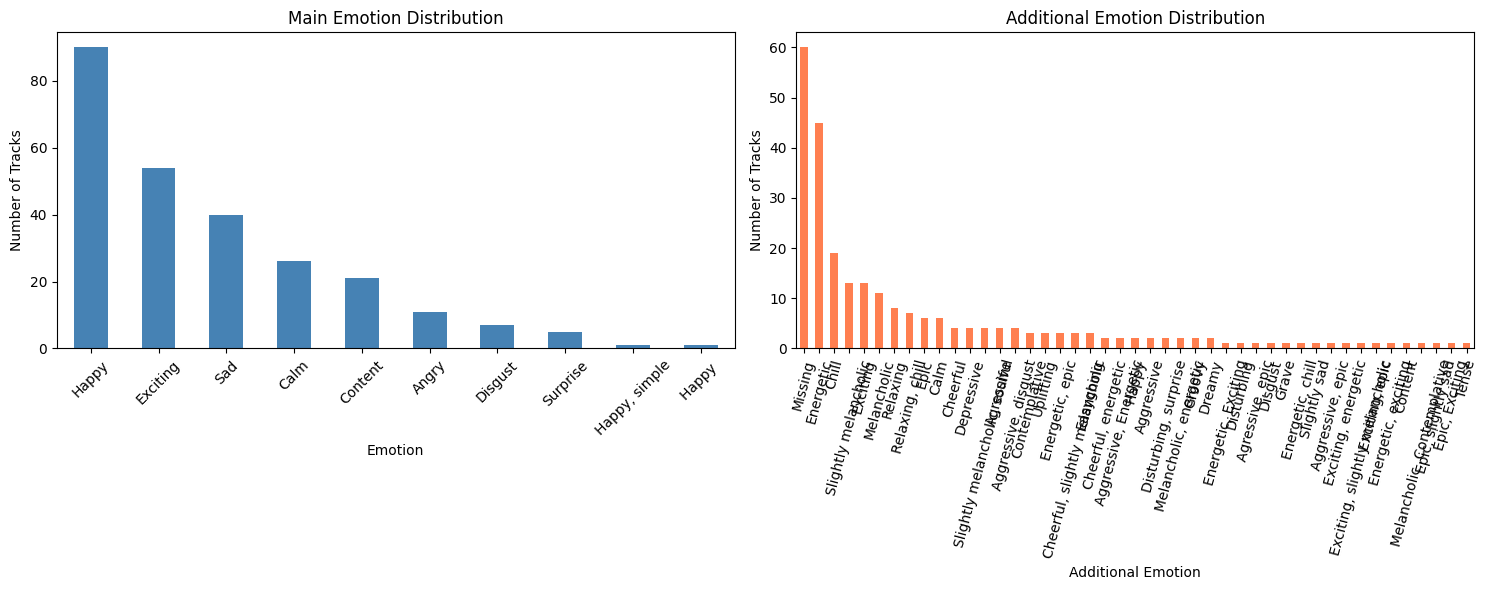

In [86]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

emotion_counts.plot(
    kind="bar",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Main Emotion Distribution")
axes[0].set_xlabel("Emotion")
axes[0].set_ylabel("Number of Tracks")
axes[0].tick_params(axis="x", rotation=45)

extra_emotion_counts.plot(
    kind="bar",
    ax=axes[1],
    color="coral"
)

axes[1].set_title("Additional Emotion Distribution")
axes[1].set_xlabel("Additional Emotion")
axes[1].set_ylabel("Number of Tracks")
axes[1].tick_params(axis="x", rotation=75)

plt.tight_layout()
plt.show()


Extra_emotion,Aggressive,"Aggressive, Energetic","Aggressive, disgust","Aggressive, epic",Agressive,"Agressive, epic",Calm,Cheerful,"Cheerful, energetic","Cheerful, slightly melancholic",...,"Melancholic, Contemplative","Melancholic, energetic",Missing,Relaxing,"Relaxing, chill",Slightly melancholic,"Slightly melancholic, soulful",Slightly sad,Tense,Uplifting
Emotion,,,,,,,,,,,,,,,,,,,,,
Angry,2,0,4,1,1,0,0,0,0,0,...,0,0,3,0,0,0,0,0,0,0
Calm,0,0,0,0,0,0,0,0,0,0,...,0,0,2,4,4,4,0,0,0,0
Content,0,0,0,0,0,0,2,0,0,0,...,0,0,7,4,2,2,0,0,0,0
Disgust,0,2,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Exciting,0,0,0,0,2,1,0,0,0,0,...,0,0,7,0,0,0,0,1,0,1
Happy,0,0,0,0,0,0,0,4,2,3,...,1,0,29,0,1,6,0,0,0,2
Happy,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"Happy, simple",0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
Sad,0,0,0,0,0,0,4,0,0,0,...,0,2,9,0,0,1,4,0,0,0


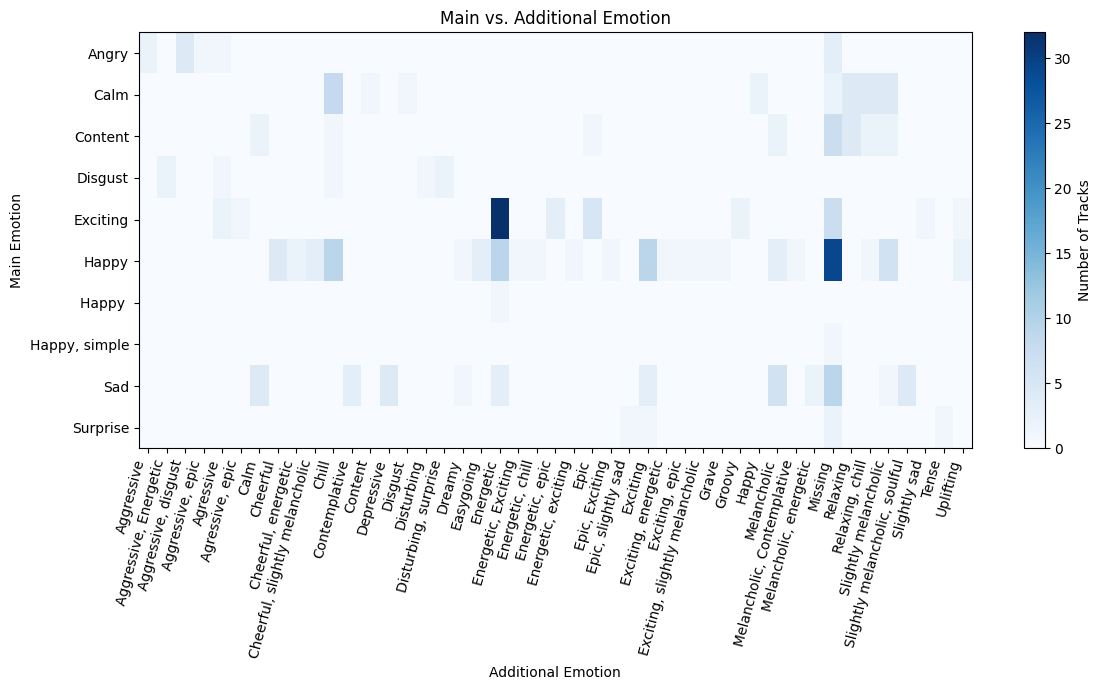

In [87]:

# Cross-tabulation of main and additional emotions
emotion_crosstab = pd.crosstab(
    df["Emotion"].fillna("Missing"),
    df["Extra_emotion"].fillna("Missing")
)

display(emotion_crosstab)

# Visualize the relationship
plt.figure(figsize=(12, 7))

plt.imshow(
    emotion_crosstab,
    aspect="auto",
    cmap="Blues"
)

plt.colorbar(label="Number of Tracks")

plt.xticks(
    range(len(emotion_crosstab.columns)),
    emotion_crosstab.columns,
    rotation=75,
    ha="right"
)

plt.yticks(
    range(len(emotion_crosstab.index)),
    emotion_crosstab.index
)

plt.title("Main vs. Additional Emotion")
plt.xlabel("Additional Emotion")
plt.ylabel("Main Emotion")

plt.tight_layout()
plt.show()


In [88]:

emotion_summary = pd.DataFrame({
    "Feature": ["Emotion", "Extra_emotion"],
    "Non-missing": [
        df["Emotion"].notna().sum(),
        df["Extra_emotion"].notna().sum()
    ],
    "Missing": [
        df["Emotion"].isna().sum(),
        df["Extra_emotion"].isna().sum()
    ],
    "Unique non-missing labels": [
        df["Emotion"].nunique(),
        df["Extra_emotion"].nunique()
    ]
})

emotion_summary["Availability (%)"] = (
    emotion_summary["Non-missing"] / len(df) * 100
).round(2)

display(emotion_summary)


,Feature,Non-missing,Missing,Unique non-missing labels,Availability (%)
0,Emotion,256,0,10,100.00
1,Extra_emotion,196,60,44,76.56



### Findings

The emotion distribution analysis examines the frequency, availability, and diversity of emotional annotations in SunoCaps.

The results help identify whether certain emotional classes are overrepresented and whether additional emotion labels provide complementary information.

Class imbalance should be considered when evaluating future emotion classification models. Metrics such as macro-F1 can provide a more balanced assessment than accuracy alone.

The next step will investigate vocal characteristics and determine which vocal-related labels are available for evaluation.


#### 1.7.1. Emotion Label Normalization

**Objective:** Standardize emotion annotations to ensure consistent statistical analysis and future model evaluation.

The initial EDA revealed inconsistent capitalization, trailing whitespace, spelling variations, and multi-label emotion descriptions.

We normalize the main emotion labels and split additional emotion descriptions into individual attributes, while preserving the original dataset columns.

This preprocessing enables more reliable frequency analysis and supports future multi-label emotion evaluation.


In [89]:

# Preserve original annotations
df["Emotion_clean"] = (
    df["Emotion"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Split combined main labels into emotion + descriptor
df["Emotion_clean"] = (
    df["Emotion_clean"]
    .str.split(",")
    .str[0]
    .str.strip()
)

# Normalize additional emotion labels
def normalize_extra_emotions(value):
    if pd.isna(value) or not str(value).strip():
        return []

    labels = [
        label.strip().lower()
        for label in str(value).split(",")
    ]

    corrections = {
        "agressive": "aggressive"
    }

    return [
        corrections.get(label, label)
        for label in labels
        if label
    ]

df["Extra_emotion_clean"] = (
    df["Extra_emotion"]
    .apply(normalize_extra_emotions)
)

# Check cleaned main emotion labels
print("CLEANED MAIN EMOTIONS:")
display(df["Emotion_clean"].value_counts())

# Count individual additional emotions
extra_emotions = (
    df["Extra_emotion_clean"]
    .explode()
    .dropna()
)

print("\nCLEANED ADDITIONAL EMOTIONS:")
display(extra_emotions.value_counts())

print("\nUnique main emotions:",
      df["Emotion_clean"].nunique())

print("Unique additional emotions:",
      extra_emotions.nunique())


CLEANED MAIN EMOTIONS:


Emotion_clean
happy       92
exciting    54
sad         40
calm        26
content     21
angry       11
disgust      7
surprise     5
Name: count, dtype: int64


CLEANED ADDITIONAL EMOTIONS:


Extra_emotion_clean
energetic               58
chill                   27
slightly melancholic    21
exciting                19
relaxing                15
epic                    14
aggressive              14
melancholic             14
cheerful                 9
calm                     6
disgust                  5
contemplative            4
soulful                  4
depressive               4
uplifting                3
easygoing                3
disturbing               3
happy                    2
dreamy                   2
groovy                   2
slightly sad             2
surprise                 2
tense                    1
content                  1
grave                    1
Name: count, dtype: int64


Unique main emotions: 8
Unique additional emotions: 25


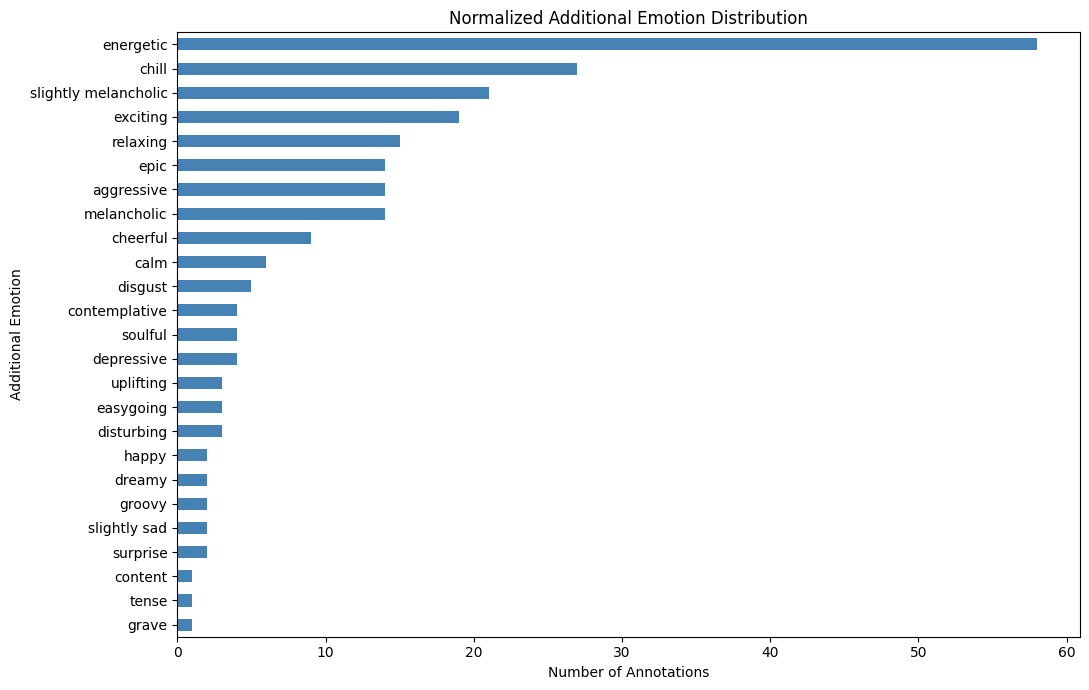

In [90]:

clean_extra_counts = extra_emotions.value_counts()

plt.figure(figsize=(11, 7))

clean_extra_counts.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.xlabel("Number of Annotations")
plt.ylabel("Additional Emotion")
plt.title("Normalized Additional Emotion Distribution")
plt.tight_layout()
plt.show()



#### Findings

The emotion annotations were normalized to address inconsistent formatting, spelling variations, and multi-label descriptions.

The original `Emotion` and `Extra_emotion` columns were preserved, while cleaned versions were created for further analysis.

The main emotion distribution exhibits class imbalance, with Happy, Exciting, and Sad being the most frequent categories.

Additional emotion labels provide more detailed emotional descriptions, but 60 tracks have no additional emotion annotation.

These findings suggest that future emotion classification experiments should account for imbalanced classes and distinguish single-label from multi-label evaluation.


### 1.8. Vocal Characteristics Distribution

**Objective:** Examine vocal-related information available in the SunoCaps dataset.

Vocal characteristics are important for evaluating whether generated music follows prompt requirements related to singing, instrumental arrangements, and vocal presence.

At this stage, we aim to:
- Identify available vocal-related features.
- Examine their data types and distributions.
- Assess whether vocal annotations can support supervised evaluation.

We distinguish dataset-provided annotations from information inferred through prompt text or expert comments.


In [91]:

# Inspect all original dataset columns
print("ALL DATASET COLUMNS:")

for col in df.columns:
    print(f"{col}: {df[col].dtype}")

# Identify possible vocal-related features
vocal_keywords = [
    "vocal", "voice", "sing",
    "instrumental", "lyrics"
]

vocal_columns = [
    col for col in df.columns
    if any(keyword in col.lower()
           for keyword in vocal_keywords)
]

print("\nPOTENTIAL VOCAL-RELATED COLUMNS:")
print(vocal_columns)

for col in vocal_columns:
    print(f"\n{col}")
    display(
        df[col].value_counts(dropna=False).head(20)
    )


ALL DATASET COLUMNS:
ytid_V: object
Comments: object
Emotion: object
Extra_emotion: object
aspect_version: bool
caption_version: bool
shorth_aspect: bool
short_caption: bool
Instrumental: bool
aspect_list: object
caption: object
original_id: object
generation_version: object
Emotion_clean: object
Extra_emotion_clean: object

POTENTIAL VOCAL-RELATED COLUMNS:
['Instrumental']

Instrumental


Instrumental
False    194
True      62
Name: count, dtype: int64

In [92]:

import re

VOCAL_PATTERNS = {
    "instrumental": r"\binstrumental\b",
    "male_vocals": r"\b(male voice|male singer|male vocal|man singing)\b",
    "female_vocals": r"\b(female voice|female singer|female vocal|woman singing)\b",
    "singing": r"\b(singing|singer|vocals?)\b",
    "no_vocals": r"\b(no vocals?|no singer|without vocals?|no singing)\b"
}

# Combine prompt representations for exploratory keyword analysis
df["prompt_combined"] = (
    df["caption"].fillna("") + " " +
    df["aspect_list"].fillna("")
).str.lower()

for label, pattern in VOCAL_PATTERNS.items():
    df[f"prompt_{label}"] = (
        df["prompt_combined"]
        .str.contains(pattern, regex=True, na=False)
    )

vocal_prompt_counts = pd.Series({
    label: int(df[f"prompt_{label}"].sum())
    for label in VOCAL_PATTERNS
})

display(
    vocal_prompt_counts.to_frame("Number of Tracks")
)


/var/folders/9t/smzhpxbj147fk1w2htxb4mnr0000gn/T/ipykernel_68190/3246670244.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(pattern, regex=True, na=False)
/var/folders/9t/smzhpxbj147fk1w2htxb4mnr0000gn/T/ipykernel_68190/3246670244.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(pattern, regex=True, na=False)
/var/folders/9t/smzhpxbj147fk1w2htxb4mnr0000gn/T/ipykernel_68190/3246670244.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(pattern, regex=True, na=False)
/var/folders/9t/smzhpxbj147fk1w2htxb4mnr0000gn/T/ipykernel_68190/3246670244.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extr

,Number of Tracks
instrumental,56
male_vocals,80
female_vocals,32
singing,140
no_vocals,4



#### Findings

The SunoCaps dataset contains an `Instrumental` boolean feature, with 62 tracks labeled True (24.2%) and 194 labeled False (75.8%).

Text analysis revealed frequent references to singing and vocal characteristics, including male and female voices.

However, the dataset-provided instrumental label and prompt-derived vocal requirements represent different sources of information and should not be interpreted as equivalent without checking their definitions.

These findings suggest that vocal presence is an important characteristic for the planned validation framework.


### 1.9. Caption vs. Aspect-List Comparison

**Objective:** Compare the structure, length, and generation configurations of caption-based and aspect-list-based prompts.

SunoCaps provides two descriptions for each original music sample:
- `caption`: A natural-language music description.
- `aspect_list`: A list of musical attributes.

We examine their textual characteristics and investigate how generation versions are associated with the dataset's configuration flags.

This comparison will help determine how to evaluate prompt-to-audio alignment for different prompt representations.


In [93]:

# Generation configuration columns
config_cols = [
    "aspect_version",
    "caption_version",
    "shorth_aspect",
    "short_caption"
]

print("GENERATION CONFIGURATIONS:")

display(
    df.groupby(config_cols, dropna=False)
    .size()
    .reset_index(name="track_count")
)

print("\nCONFIGURATIONS BY GENERATION VERSION:")

display(
    df.groupby(
        ["generation_version"] + config_cols,
        dropna=False
    )
    .size()
    .reset_index(name="track_count")
)


GENERATION CONFIGURATIONS:


,aspect_version,caption_version,shorth_aspect,short_caption,track_count
0,False,True,False,False,12
1,False,True,False,True,84
2,False,True,True,False,2
3,False,True,True,True,30
4,True,False,False,False,12
5,True,False,False,True,82
6,True,False,True,False,2
7,True,False,True,True,30
8,True,True,False,True,2



CONFIGURATIONS BY GENERATION VERSION:


,generation_version,aspect_version,caption_version,shorth_aspect,short_caption,track_count
0,1,True,False,False,False,6
1,1,True,False,False,True,41
2,1,True,False,True,False,1
3,1,True,False,True,True,15
4,1,True,True,False,True,1
5,2,True,False,False,False,6
6,2,True,False,False,True,41
7,2,True,False,True,False,1
8,2,True,False,True,True,15
9,2,True,True,False,True,1


In [94]:

# Create a copy for prompt comparison
prompt_df = df.copy()

prompt_df["caption_words"] = (
    prompt_df["caption"]
    .fillna("")
    .str.split()
    .str.len()
)

prompt_df["aspect_words"] = (
    prompt_df["aspect_list"]
    .fillna("")
    .str.split()
    .str.len()
)

# Avoid counting four generations of the same prompt
unique_prompts = prompt_df.drop_duplicates(
    subset=["original_id"]
).copy()

length_comparison = pd.DataFrame({
    "Prompt Type": ["Caption", "Aspect List"],
    "Mean Words": [
        unique_prompts["caption_words"].mean(),
        unique_prompts["aspect_words"].mean()
    ],
    "Median Words": [
        unique_prompts["caption_words"].median(),
        unique_prompts["aspect_words"].median()
    ],
    "Min Words": [
        unique_prompts["caption_words"].min(),
        unique_prompts["aspect_words"].min()
    ],
    "Max Words": [
        unique_prompts["caption_words"].max(),
        unique_prompts["aspect_words"].max()
    ]
}).round(2)

display(length_comparison)


,Prompt Type,Mean Words,Median Words,Min Words,Max Words
0,Caption,30.86,31.0,22,38
1,Aspect List,18.59,18.0,7,29


ASPECT COUNT STATISTICS:


count    64.000000
mean      9.890625
std       2.917474
min       4.000000
25%       8.000000
50%       9.500000
75%      12.000000
max      17.000000
Name: aspect_count, dtype: float64

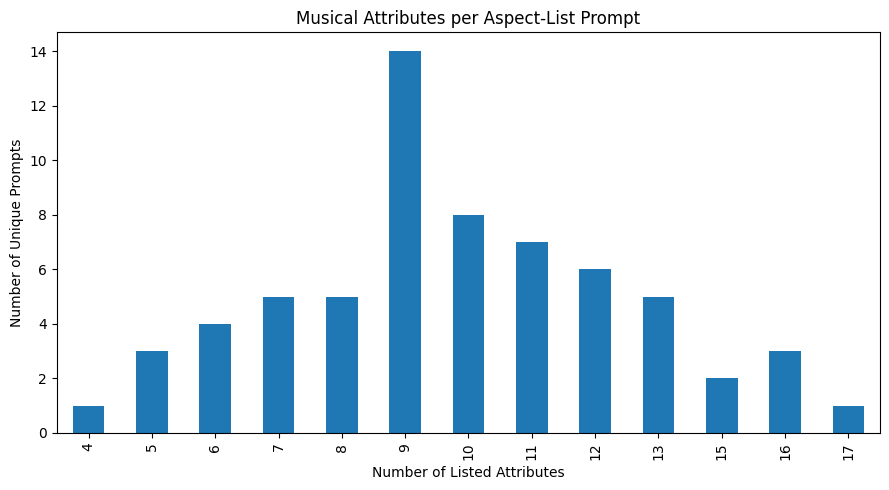

In [95]:

unique_prompts["aspect_count"] = (
    unique_prompts["aspect_list"]
    .fillna("")
    .apply(
        lambda text: len([
            item.strip()
            for item in text.split(",")
            if item.strip()
        ])
    )
)

print("ASPECT COUNT STATISTICS:")
display(
    unique_prompts["aspect_count"].describe()
)

plt.figure(figsize=(9, 5))

unique_prompts["aspect_count"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("Number of Listed Attributes")
plt.ylabel("Number of Unique Prompts")
plt.title("Musical Attributes per Aspect-List Prompt")
plt.tight_layout()
plt.show()



#### Findings

SunoCaps contains four generated versions per original music description. Versions 1 and 2 use aspect-list prompts, while versions 3 and 4 use caption-based prompts.

Natural-language captions contain an average of 30.86 words, compared with 18.59 words in aspect lists.

A small inconsistency was identified in the generation configuration flags, where two tracks were marked as both caption-based and aspect-based.

For subsequent analysis, generation version is used to determine the prompt type.

The two representations differ substantially in length and structure, motivating separate prompt parsing strategies and comparisons of validation performance.


### 1.10. Prompt Characteristics and Expert Feedback

**Objective:** Compare expert feedback availability between caption-based and aspect-list-based generations.

We examine the proportion of tracks with expert comments for each prompt representation.

In [96]:

# Define prompt type using generation version
df["prompt_type"] = df["generation_version"].map({
    "1": "Aspect List",
    "2": "Aspect List",
    "3": "Caption",
    "4": "Caption"
})

# Identify tracks with expert comments
df["has_expert_comment"] = (
    df["Comments"].notna()
    & df["Comments"].astype("string").str.strip().ne("")
).fillna(False)


# Preliminary mismatch indicators based on expert comments
df["has_expert_comment"] = (
    df["Comments"].notna()
    & df["Comments"].astype("string").str.strip().ne("")
).fillna(False)

# Create an exploratory indicator independent of Stage 2
df["has_reported_feedback"] = df["has_expert_comment"]

print("TRACKS BY PROMPT TYPE:")
display(df["prompt_type"].value_counts(dropna=False))

print("\nEXPERT COMMENT AVAILABILITY:")
display(
    pd.crosstab(
        df["prompt_type"],
        df["has_expert_comment"],
        margins=True
    )
)


TRACKS BY PROMPT TYPE:


prompt_type
Aspect List    128
Caption        128
Name: count, dtype: int64


EXPERT COMMENT AVAILABILITY:


has_expert_comment,False,True,All
prompt_type,,,
Aspect List,37,91,128
Caption,36,92,128
All,73,183,256


In [97]:

feedback_summary = (
    df.groupby("prompt_type")
    .agg(
        tracks=("ytid_V", "count"),
        commented_tracks=("has_expert_comment", "sum")
    )
)

feedback_summary["comment_rate_pct"] = (
    feedback_summary["commented_tracks"]
    / feedback_summary["tracks"] * 100
)

display(feedback_summary.round(2))


,tracks,commented_tracks,comment_rate_pct
prompt_type,,,
Aspect List,128,91,71.09
Caption,128,92,71.88



#### Findings

The dataset contains an equal number of caption-based and aspect-list-based generations (128 tracks each).

Expert comments are available for 71.09% of aspect-list generations and 71.88% of caption-based generations.

The difference in comment availability is small (0.79 percentage points), suggesting similar feedback coverage across prompt representations.

However, expert comment availability does not directly measure generation quality. Detailed mismatch extraction and comparison are performed in Stage 2.


### 1.11. EDA Summary and Key Findings

**Objective:** Summarize the main characteristics, data quality limitations, and modeling implications identified during exploratory data analysis.

#### Dataset Structure

The SunoCaps dataset contains 256 generated tracks derived from 64 original music descriptions, with four generated versions per source.

Two versions use aspect-list prompts, while the other two use natural-language captions, resulting in 128 tracks per prompt representation.

Captions contain approximately 30.86 words on average, compared with 18.59 words for aspect lists.

#### Emotion Annotations

The dataset contains eight normalized main emotion categories and 25 unique additional emotion descriptors.

The most frequent main emotions are Happy (92 tracks), Exciting (54), and Sad (40).

Main emotion annotations are available for all tracks, while additional emotion annotations are present for 196 out of 256 tracks (76.56%).

The emotion distribution is imbalanced, which should be considered during model evaluation.

#### Vocal Characteristics

The dataset contains a boolean `Instrumental` feature, with 62 tracks labeled as instrumental and 194 as non-instrumental.

Vocal-related requirements also appear frequently in text prompts, including references to singing, male and female voices, and instrumental arrangements.

The precise meaning of the `Instrumental` annotation must be verified before using it as evaluation ground truth.

#### Expert Feedback

Expert comments are available for 183 of 256 tracks (71.48%), while 73 tracks have no comments.

Comment availability is similar between aspect-list-based (71.09%) and caption-based (71.88%) generations.

Since expert comments are incomplete, missing feedback cannot be interpreted as successful prompt adherence.

Detailed mismatch extraction and annotation validation are performed separately in Stage 2.

#### Prompt Representation Comparison

Caption-based and aspect-list-based generations show similar expert comment availability (71.88% versus 71.09%).

The preliminary mismatch extraction rates are 42.97% for captions and 38.28% for aspect lists.

These differences are descriptive and do not establish a statistically significant difference in generation quality.

#### Implications for Model Development

The EDA highlights several requirements for the proposed validation framework:

1. Separate parsing strategies are needed for captions and aspect lists.
2. Emotion classification should account for class imbalance.
3. Expert comments require structured extraction and manual verification.
4. Prompt requirements must distinguish explicit constraints from unspecified characteristics.
5. Evaluation splits must preserve the grouping of generated tracks by their original music description.
6. Model evaluation should distinguish annotation availability from actual generation correctness.

Overall, SunoCaps provides a useful foundation for developing and evaluating a modular prompt-to-audio validation framework, although the limited dataset size and incomplete expert feedback introduce important methodological constraints.


In [98]:

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

df.to_pickle(output_dir / "sunocaps_eda.pkl")

print("EDA dataset saved successfully.")
print("Shape:", df.shape)

EDA dataset saved successfully.
Shape: (256, 24)
